### Liver cancer

In [ ]:
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.model_selection import StratifiedGroupKFold

##### Fsocre

In [3]:
# 加载数据集
file_path = '../Fscore/Liver_sample_FscoreSorted_selected34.csv'
Fscoredata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Fscore(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Fscore/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [6]:
Liver_leaderboard_Fscore = prepare_train_test_Fscore(Fscoredata, "Liver cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       187.83 GB / 251.54 GB (74.7%)
Disk Space Avail:   8944.10 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

(_ray_fit pid=3925131) [1000]	valid_set's binary_logloss: 0.0577973


(_dystack pid=3918767) 	0.9872	 = Validation score   (roc_auc)
(_dystack pid=3918767) 	0.89s	 = Training   runtime
(_dystack pid=3918767) 	0.01s	 = Validation runtime
(_dystack pid=3918767) Fitting model: RandomForest_BAG_L2 ... Training model for up to 879.71s of the 879.7s of remaining time.
(_dystack pid=3918767) 	0.9773	 = Validation score   (roc_auc)
(_dystack pid=3918767) 	1.77s	 = Training   runtime
(_dystack pid=3918767) 	0.1s	 = Validation runtime
(_dystack pid=3918767) Fitting model: NeuralNetFastAI_BAG_L2 ... Training model for up to 877.79s of the 877.79s of remaining time.
(_dystack pid=3918767) 	Fitting 8 child models (S1F1 - S1F8) | Fitting with ParallelLocalFoldFittingStrategy (8 workers, per: cpus=6, gpus=0, memory=0.00%)
(_dystack pid=3918767) 	0.9855	 = Validation score   (roc_auc)
(_dystack pid=3918767) 	7.59s	 = Training   runtime
(_dystack pid=3918767) 	0.18s	 = Validation runtime
(_dystack pid=3918767) Fitting model: XGBoost_BAG_L2 ... Training model for up to 86

In [7]:
Liver_leaderboard_Fscore.to_csv("Liver_leaderboard_Fscore.csv", index=False)
Liver_leaderboard_Fscore

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,RandomForest_BAG_L1,0.966472,0.918367,0.918367,0.836735,0.918367,0.918367,0.918367,0.966472,0.981131,roc_auc,0.050114,0.101279,1.373103,0.050114,0.101279,1.373103,1,True,2
1,WeightedEnsemble_L2,0.964598,0.928571,0.928571,0.857321,0.927835,0.937500,0.918367,0.964598,0.984405,roc_auc,2.462657,0.292498,12.998859,0.002551,0.000447,0.027821,2,True,5
2,NeuralNetFastAI_BAG_L1,0.960850,0.887755,0.887755,0.779579,0.881720,0.931818,0.836735,0.960850,0.957160,roc_auc,1.857484,0.155781,9.299657,1.857484,0.155781,9.299657,1,True,3
3,LightGBM_BAG_L1,0.956268,0.918367,0.918367,0.837433,0.916667,0.936170,0.897959,0.956268,0.982459,roc_auc,0.195466,0.009435,0.726830,0.195466,0.009435,0.726830,1,True,1
4,XGBoost_BAG_L1,0.950021,0.908163,0.908163,0.816497,0.909091,0.900000,0.918367,0.950021,0.978422,roc_auc,0.357041,0.025557,1.571448,0.357041,0.025557,1.571448,1,True,4


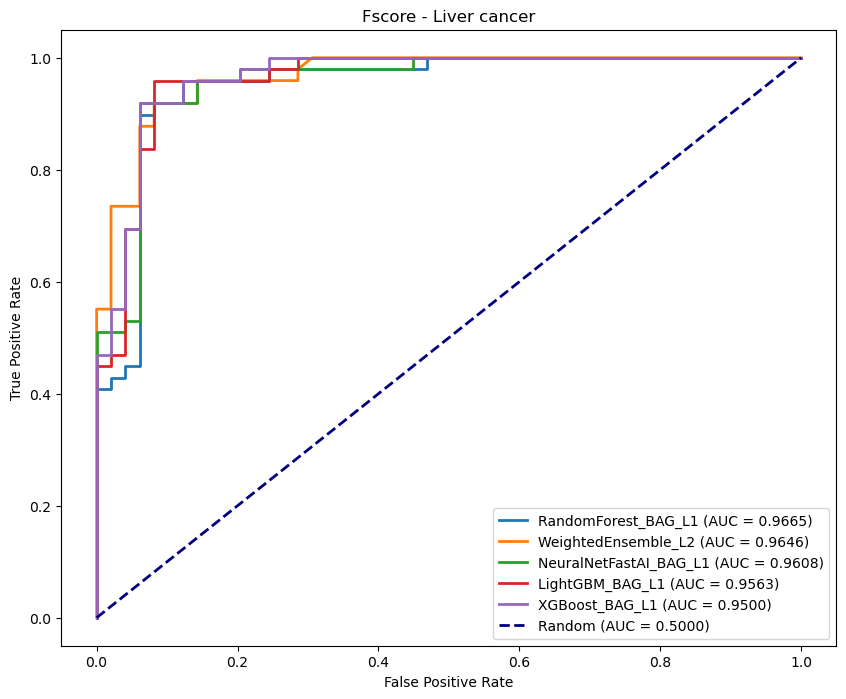

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Fscore(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)  # 只取正类概率
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Fscore - Liver cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/Fscore'
data = Fscoredata 
plot_roc_curves_Fscore(data, model_dir)


##### ANOVA

In [6]:
# 加载数据集
file_path = '../ANOVA/Liver_sample_AnovaSorted_selected34.csv'
ANOVAdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ANOVA(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ANOVA/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [11]:
Liver_leaderboard_ANOVA = prepare_train_test_ANOVA(ANOVAdata, "Liver cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       187.06 GB / 251.54 GB (74.4%)
Disk Space Avail:   8944.08 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

Leaderboard on holdout data (DyStack):
                      model  score_holdout  score_val eval_metric  pred_time_test  pred_time_val   fit_time  pred_time_test_marginal  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0       RandomForest_BAG_L1       1.000000   0.976895     roc_auc        0.040978       0.102311   1.785846                 0.040978                0.102311           1.785846            1       True          2
1           LightGBM_BAG_L1       1.000000   0.983795     roc_auc        0.311221       0.006604   0.546350                 0.311221                0.006604           0.546350            1       True          1
2            XGBoost_BAG_L1       1.000000   0.981690     roc_auc        0.337790       0.031035   1.724522                 0.337790                0.031035           1.724522            1       True          4
3       WeightedEnsemble_L2       1.000000   0.985332     roc_auc        3.169857       0.198617   8.829567          

In [12]:
Liver_leaderboard_ANOVA.to_csv("Liver_leaderboard_ANOVA.csv", index=False)
Liver_leaderboard_ANOVA

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,RandomForest_BAG_L1,0.966472,0.918367,0.918367,0.836735,0.918367,0.918367,0.918367,0.966472,0.981131,roc_auc,0.052388,0.102540,1.282625,0.052388,0.102540,1.282625,1,True,2
1,WeightedEnsemble_L2,0.964598,0.928571,0.928571,0.857321,0.927835,0.937500,0.918367,0.964598,0.984405,roc_auc,1.115124,0.238501,9.311493,0.002578,0.000434,0.023696,2,True,5
2,NeuralNetFastAI_BAG_L1,0.960850,0.887755,0.887755,0.779579,0.881720,0.931818,0.836735,0.960850,0.957160,roc_auc,0.596272,0.102007,5.813232,0.596272,0.102007,5.813232,1,True,3
3,LightGBM_BAG_L1,0.956268,0.918367,0.918367,0.837433,0.916667,0.936170,0.897959,0.956268,0.982459,roc_auc,0.130201,0.007635,0.670204,0.130201,0.007635,0.670204,1,True,1
4,XGBoost_BAG_L1,0.950021,0.908163,0.908163,0.816497,0.909091,0.900000,0.918367,0.950021,0.978422,roc_auc,0.333685,0.025885,1.521737,0.333685,0.025885,1.521737,1,True,4


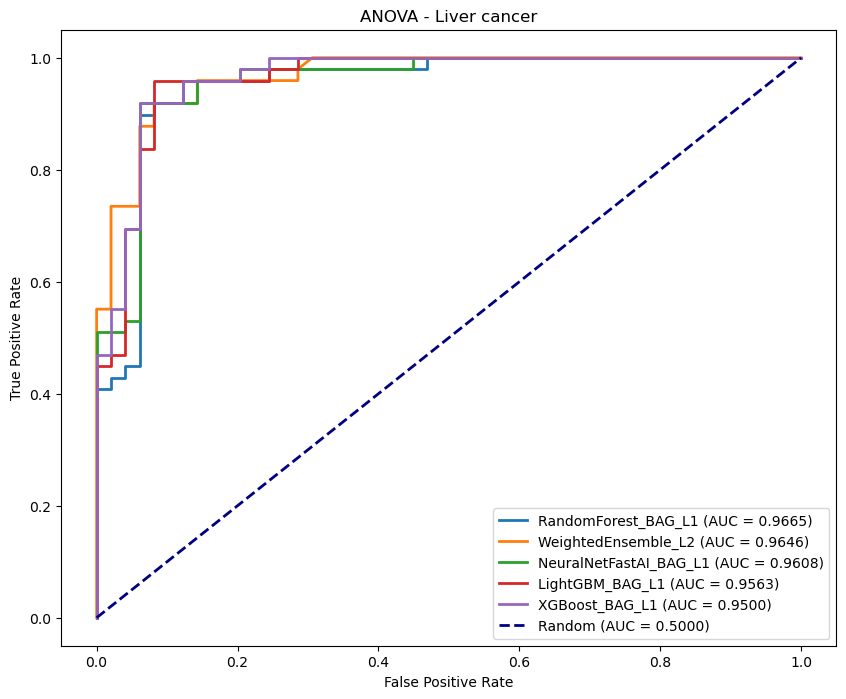

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ANOVA(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)  # 只取正类概率
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ANOVA - Liver cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/ANOVA'
data = ANOVAdata 
plot_roc_curves_ANOVA(data, model_dir)


##### ReliefF

In [3]:
# 加载数据集
file_path = '../ReliefF/Liver_sample_ReliefFSorted_selected11.csv'
ReliefFdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ReliefF(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ReliefF/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [17]:
Liver_leaderboard_ReliefF = prepare_train_test_ReliefF(ReliefFdata, "Liver cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       242.26 GB / 251.54 GB (96.3%)
Disk Space Avail:   8854.81 GB / 14784.53 GB (59.9%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

(_ray_fit pid=1801115) [1000]	valid_set's binary_logloss: 0.0305446
(_ray_fit pid=1801115) [2000]	valid_set's binary_logloss: 0.0270594
(_ray_fit pid=1801115) [3000]	valid_set's binary_logloss: 0.0259579
(_ray_fit pid=1801115) [4000]	valid_set's binary_logloss: 0.0248409
(_ray_fit pid=1801115) [5000]	valid_set's binary_logloss: 0.02285
(_ray_fit pid=1801115) [6000]	valid_set's binary_logloss: 0.0214199
(_ray_fit pid=1801115) [7000]	valid_set's binary_logloss: 0.0208876
(_ray_fit pid=1801115) [8000]	valid_set's binary_logloss: 0.0203133
(_ray_fit pid=1801115) [9000]	valid_set's binary_logloss: 0.0200411
(_ray_fit pid=1801115) [10000]	valid_set's binary_logloss: 0.0199584


(_dystack pid=1797591) 	0.9872	 = Validation score   (roc_auc)
(_dystack pid=1797591) 	1.22s	 = Training   runtime
(_dystack pid=1797591) 	0.01s	 = Validation runtime
(_dystack pid=1797591) Fitting model: RandomForest_BAG_L1 ... Training model for up to 588.37s of the 884.14s of remaining time.
(_dystack pid=1797591) 	0.9841	 = Validation score   (roc_auc)
(_dystack pid=1797591) 	1.84s	 = Training   runtime
(_dystack pid=1797591) 	0.11s	 = Validation runtime
(_dystack pid=1797591) Fitting model: NeuralNetFastAI_BAG_L1 ... Training model for up to 586.38s of the 882.16s of remaining time.
(_dystack pid=1797591) 	Fitting 8 child models (S1F1 - S1F8) | Fitting with ParallelLocalFoldFittingStrategy (8 workers, per: cpus=6, gpus=0, memory=0.00%)
(_dystack pid=1797591) 	0.9689	 = Validation score   (roc_auc)
(_dystack pid=1797591) 	6.23s	 = Training   runtime
(_dystack pid=1797591) 	0.15s	 = Validation runtime
(_dystack pid=1797591) Fitting model: XGBoost_BAG_L1 ... Training model for up to 

(_ray_fit pid=1803844) [1000]	valid_set's binary_logloss: 0.000140021


(_dystack pid=1797591) 	0.9854	 = Validation score   (roc_auc)
(_dystack pid=1797591) 	0.48s	 = Training   runtime
(_dystack pid=1797591) 	0.01s	 = Validation runtime
(_dystack pid=1797591) Fitting model: RandomForest_BAG_L2 ... Training model for up to 870.59s of the 870.58s of remaining time.
(_dystack pid=1797591) 	0.9823	 = Validation score   (roc_auc)
(_dystack pid=1797591) 	1.82s	 = Training   runtime
(_dystack pid=1797591) 	0.11s	 = Validation runtime
(_dystack pid=1797591) Fitting model: NeuralNetFastAI_BAG_L2 ... Training model for up to 868.63s of the 868.62s of remaining time.
(_dystack pid=1797591) 	Fitting 8 child models (S1F1 - S1F8) | Fitting with ParallelLocalFoldFittingStrategy (8 workers, per: cpus=6, gpus=0, memory=0.00%)
(_dystack pid=1797591) 	0.9876	 = Validation score   (roc_auc)
(_dystack pid=1797591) 	7.19s	 = Training   runtime
(_dystack pid=1797591) 	0.18s	 = Validation runtime
(_dystack pid=1797591) Fitting model: XGBoost_BAG_L2 ... Training model for up to 

In [18]:
Liver_leaderboard_ReliefF.to_csv("Liver_leaderboard_ReliefF.csv", index=False)
Liver_leaderboard_ReliefF

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,RandomForest_BAG_L1,0.992295,0.948980,0.948980,0.899647,0.950495,0.923077,0.979592,0.992295,0.987403,roc_auc,0.049054,0.103207,1.284167,0.049054,0.103207,1.284167,1,True,2
1,WeightedEnsemble_L2,0.991670,0.948980,0.948980,0.899647,0.950495,0.923077,0.979592,0.991670,0.988665,roc_auc,1.117758,0.316835,11.877567,0.002626,0.000459,0.025416,2,True,5
2,NeuralNetFastAI_BAG_L1,0.989171,0.918367,0.918367,0.839537,0.921569,0.886792,0.959184,0.989171,0.967469,roc_auc,0.657124,0.171816,7.608306,0.657124,0.171816,7.608306,1,True,3
3,XGBoost_BAG_L1,0.984173,0.928571,0.928571,0.857321,0.929293,0.920000,0.938776,0.984173,0.982853,roc_auc,0.387859,0.035914,2.465952,0.387859,0.035914,2.465952,1,True,4
4,LightGBM_BAG_L1,0.983340,0.938776,0.938776,0.877551,0.938776,0.938776,0.938776,0.983340,0.984642,roc_auc,0.021095,0.005439,0.493726,0.021095,0.005439,0.493726,1,True,1


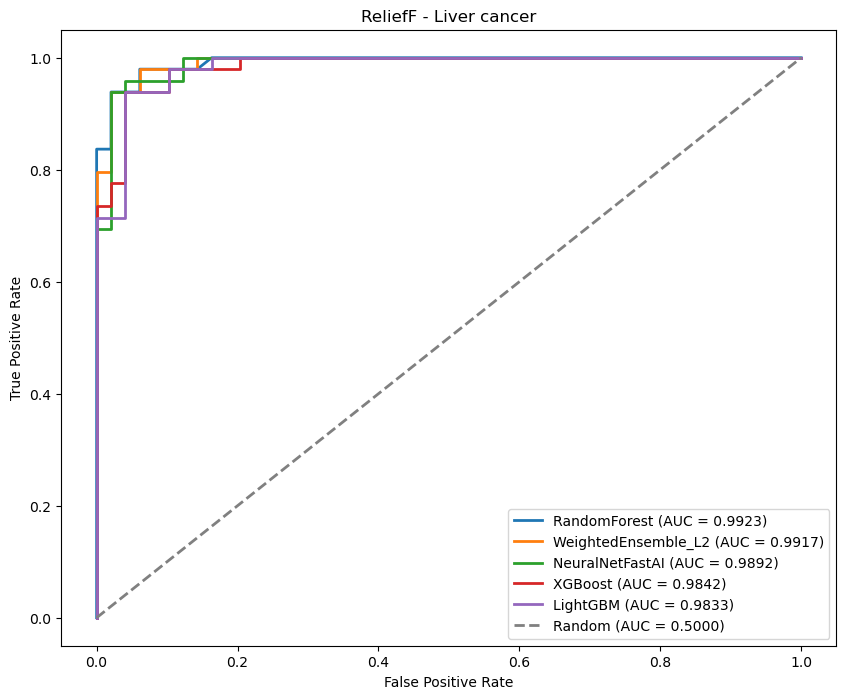

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ReliefF(data, model_dir):
    # 加载整个 predictor 对象
    ReliefF_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    plot_data = []
    
    for model_name in models:
        # 加载每个模型
        model = ReliefF_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        clean_name = model_name.replace('_BAG_L1', '').replace('_L1', '')
        plot_data.append((roc_auc, fpr, tpr, clean_name))

    plot_data.append((0.5, [0, 1], [0, 1], 'Random'))

    # 按 AUC 值降序排列
    plot_data.sort(reverse=True, key=lambda x: x[0])

    for roc_auc, fpr, tpr, label in plot_data:
        if label.lower() == 'random':
            plt.plot(fpr, tpr, lw=2, linestyle='--', color='gray', label=f'{label} (AUC = {roc_auc:.4f})')
        else:
            plt.plot(fpr, tpr, lw=2, label=f'{label} (AUC = {roc_auc:.4f})')

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ReliefF - Liver cancer')

    plt.legend(loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/ReliefF'
data = ReliefFdata 
plot_roc_curves_ReliefF(data, model_dir)


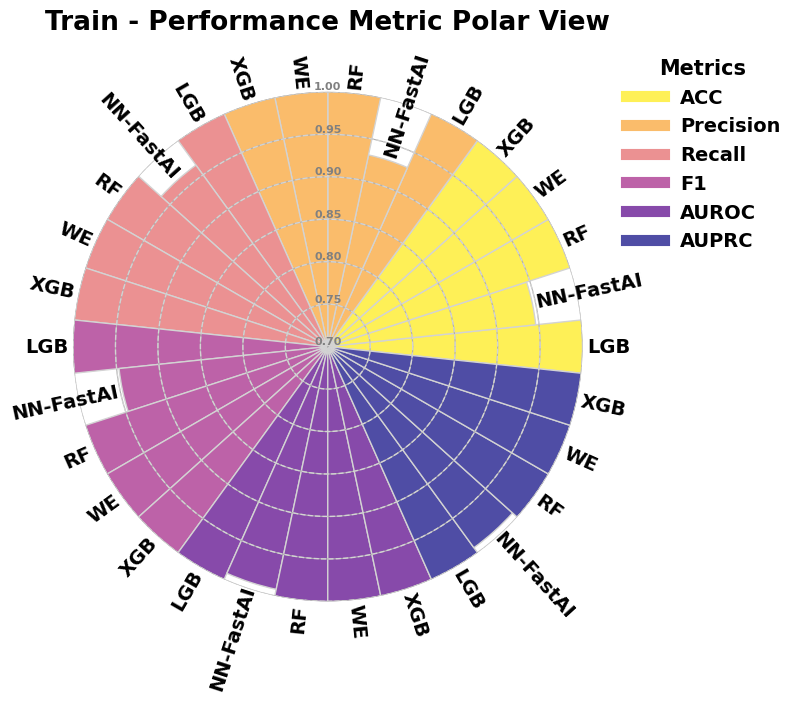

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    f1_score, recall_score, precision_score
)
from sklearn.model_selection import train_test_split
from autogluon.tabular import TabularPredictor
from matplotlib.cm import get_cmap

def compute_metrics(y_true, y_pred, y_prob):
    return {
        'AUPRC': average_precision_score(y_true, y_prob),
        'AUROC': roc_auc_score(y_true, y_prob),
        'ACC': accuracy_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred)
    }

def plot_polar_bars(data, num_metrics, num_models):
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # 角度间隔
    theta = np.linspace(0.0, 2 * np.pi, num_metrics * num_models, endpoint=False)
    radii = data['Score'].values
    width = (2 * np.pi) / (num_metrics * num_models)

    # 指标颜色映射
    colors = {
        'ACC': '#FEF057',
        'Precision': '#FABC6B',
        'Recall': '#EB9192',
        'F1': '#BD62A8',
        'AUROC': '#874AAA',
        'AUPRC': "#4F4DA5"
    }

    # 设置极坐标半径范围，从 0.8 到 1.0
    ax.set_ylim(0.7, 1.0)

    # 添加同心圆网格线与标签（用于对比高度）
    for r in np.arange(0.7, 1.01, 0.05):
        ax.plot(np.linspace(0, 2*np.pi, 500), [r]*500,
                linestyle='--', color='lightgray', linewidth=1)
        ax.text(np.pi/2, r, f"{r:.2f}", color='gray', fontsize=8,
                ha='center', va='bottom', fontweight='bold')


    # 画柱状图
    # bars = ax.bar(theta, radii, width=width, color=[colors[m] for m in data['Metric']], edgecolor='lightgray', linewidth=1.5)
    bars = ax.bar(theta, radii - 0.7, width=width, bottom=0.7,
              color=[colors[m] for m in data['Metric']],
              edgecolor='lightgray', linewidth=1)


    # 删除默认刻度
    ax.set_yticklabels([])
    ax.set_xticks([])

    # 移除最外层黑边
    ax.spines['polar'].set_visible(False)

    # 添加模型名标签并正向显示
    for i, (angle, row) in enumerate(zip(theta, data.itertuples())):
        rotation = np.degrees(angle)
        if 90 < rotation < 270:
            rotation += 180
            ha = 'right'
        else:
            ha = 'left'
        ax.text(angle, row.Score + 0.005, row.Model, ha=ha, va='center', fontsize=14, fontweight='bold', rotation=rotation, rotation_mode='anchor')


    # 图例
    handles = [plt.Line2D([0], [0], color=c, lw=8) for c in colors.values()]
    labels = list(colors.keys())
    ax.legend(handles, labels,
            loc='upper left',
            bbox_to_anchor=(1.05, 1.1),
            frameon=False,
            title="Metrics",
            title_fontproperties={'weight': 'bold', 'size': 15},
            prop={'weight': 'bold', 'size': 14})


    plt.title("Train - Performance Metric Polar View", fontsize=19, fontweight='bold', pad=45)

    # 添加中心空白圆环（遮罩）
    # center_circle = plt.Circle((0, 0), 0.2, transform=ax.transData._b, color='white', zorder=3)
    # ax.add_artist(center_circle)

    plt.tight_layout()
    plt.savefig("Model_Metric_Polar_Plot_Train.png", dpi=300)
    plt.show()

def run_and_plot_polar(data, model_dir):
    predictor = TabularPredictor.load(model_dir)
    raw_models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1',
                  'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

    # 模型名称映射
    model_name_map = {
        'XGBoost_BAG_L1': 'XGB',
        'RandomForest_BAG_L1': 'RF',
        'LightGBM_BAG_L1': 'LGB',
        'NeuralNetFastAI_BAG_L1': 'NN-FastAI',
        'WeightedEnsemble_L2': 'WE'
    }

    # 数据划分
    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)

    results = []
    for model in raw_models:
        try:
            y_true = train_data['class']
            y_pred = predictor.predict(train_data, model=model)
            y_prob_df = predictor.predict_proba(train_data, model=model)

            y_prob = y_prob_df.iloc[:, 1] if isinstance(y_prob_df, pd.DataFrame) else y_prob_df

            scores = compute_metrics(y_true, y_pred, y_prob)
            for metric, score in scores.items():
                results.append({
                    'Model': model_name_map[model],
                    'Metric': metric,
                    'Score': score
                })
        except Exception as e:
            print(f"Model {model} failed: {e}")

    results_df = pd.DataFrame(results)

    # 排序以确保指标分组连续
    metric_order = ['ACC', 'Precision', 'Recall', 'F1', 'AUROC', 'AUPRC']
    results_df['Metric'] = pd.Categorical(results_df['Metric'], categories=metric_order, ordered=True)
    results_df.sort_values(['Metric', 'Model'], inplace=True)

    # 画图
    plot_polar_bars(results_df, num_metrics=6, num_models=5)

# === 调用 ===
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/ReliefF'
data = ReliefFdata
run_and_plot_polar(data, model_dir)

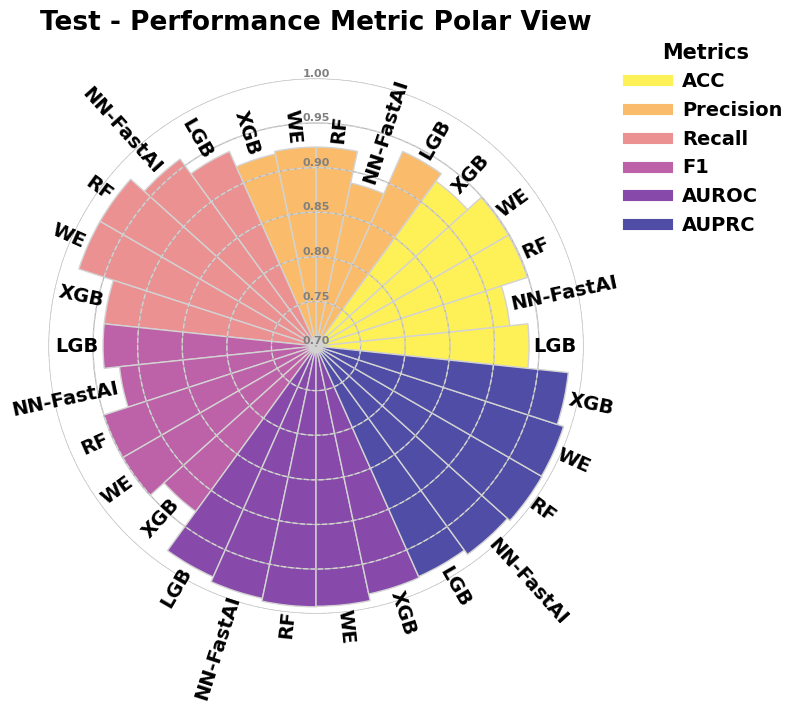

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    f1_score, recall_score, precision_score
)
from sklearn.model_selection import train_test_split
from autogluon.tabular import TabularPredictor
from matplotlib.cm import get_cmap

def compute_metrics(y_true, y_pred, y_prob):
    return {
        'AUPRC': average_precision_score(y_true, y_prob),
        'AUROC': roc_auc_score(y_true, y_prob),
        'ACC': accuracy_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred)
    }

def plot_polar_bars(data, num_metrics, num_models):
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # 角度间隔
    theta = np.linspace(0.0, 2 * np.pi, num_metrics * num_models, endpoint=False)
    radii = data['Score'].values
    width = (2 * np.pi) / (num_metrics * num_models)

    # 指标颜色映射
    colors = {
        'ACC': '#FEF057',
        'Precision': '#FABC6B',
        'Recall': '#EB9192',
        'F1': '#BD62A8',
        'AUROC': '#874AAA',
        'AUPRC': "#4F4DA5"
    }

    # 设置极坐标半径范围，从 0.7 到 1.0
    ax.set_ylim(0.7, 1.0)

    # 添加同心圆网格线与标签（用于对比高度）
    for r in np.arange(0.7, 1.01, 0.05):
        ax.plot(np.linspace(0, 2*np.pi, 500), [r]*500,
                linestyle='--', color='lightgray', linewidth=1)
        ax.text(np.pi/2, r, f"{r:.2f}", color='gray', fontsize=8,
                ha='center', va='bottom', fontweight='bold')


    # 画柱状图
    # bars = ax.bar(theta, radii, width=width, color=[colors[m] for m in data['Metric']], edgecolor='lightgray', linewidth=1.5)
    bars = ax.bar(theta, radii - 0.7, width=width, bottom=0.7,
              color=[colors[m] for m in data['Metric']],
              edgecolor='lightgray', linewidth=1)


    # 删除默认刻度
    ax.set_yticklabels([])
    ax.set_xticks([])

    # 移除最外层黑边
    ax.spines['polar'].set_visible(False)

    # 添加模型名标签并正向显示
    for i, (angle, row) in enumerate(zip(theta, data.itertuples())):
        rotation = np.degrees(angle)
        if 90 < rotation < 270:
            rotation += 180
            ha = 'right'
        else:
            ha = 'left'
        ax.text(angle, row.Score + 0.005, row.Model, ha=ha, va='center', fontsize=14, fontweight='bold', rotation=rotation, rotation_mode='anchor')


    # 图例
    handles = [plt.Line2D([0], [0], color=c, lw=8) for c in colors.values()]
    labels = list(colors.keys())
    ax.legend(handles, labels,
            loc='upper left',
            bbox_to_anchor=(1.05, 1.1),
            frameon=False,
            title="Metrics",
            title_fontproperties={'weight': 'bold', 'size': 15},
            prop={'weight': 'bold', 'size': 14})


    plt.title("Test - Performance Metric Polar View", fontsize=19, fontweight='bold', pad=35)

    # 添加中心空白圆环（遮罩）
    # center_circle = plt.Circle((0, 0), 0.2, transform=ax.transData._b, color='white', zorder=3)
    # ax.add_artist(center_circle)

    plt.tight_layout()
    plt.savefig("Model_Metric_Polar_Plot_Test.png", dpi=300)
    plt.show()

def run_and_plot_polar(data, model_dir):
    predictor = TabularPredictor.load(model_dir)
    raw_models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1',
                  'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

    # 模型名称映射
    model_name_map = {
        'XGBoost_BAG_L1': 'XGB',
        'RandomForest_BAG_L1': 'RF',
        'LightGBM_BAG_L1': 'LGB',
        'NeuralNetFastAI_BAG_L1': 'NN-FastAI',
        'WeightedEnsemble_L2': 'WE'
    }

    # 数据划分
    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)

    results = []
    for model in raw_models:
        try:
            y_true = test_data['class']
            y_pred = predictor.predict(test_data, model=model)
            y_prob_df = predictor.predict_proba(test_data, model=model)

            y_prob = y_prob_df.iloc[:, 1] if isinstance(y_prob_df, pd.DataFrame) else y_prob_df

            scores = compute_metrics(y_true, y_pred, y_prob)
            for metric, score in scores.items():
                results.append({
                    'Model': model_name_map[model],
                    'Metric': metric,
                    'Score': score
                })
        except Exception as e:
            print(f"Model {model} failed: {e}")

    results_df = pd.DataFrame(results)

    # 排序以确保指标分组连续
    metric_order = ['ACC', 'Precision', 'Recall', 'F1', 'AUROC', 'AUPRC']
    results_df['Metric'] = pd.Categorical(results_df['Metric'], categories=metric_order, ordered=True)
    results_df.sort_values(['Metric', 'Model'], inplace=True)

    # 画图
    plot_polar_bars(results_df, num_metrics=6, num_models=5)

# === 调用 ===
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/ReliefF'
data = ReliefFdata
run_and_plot_polar(data, model_dir)

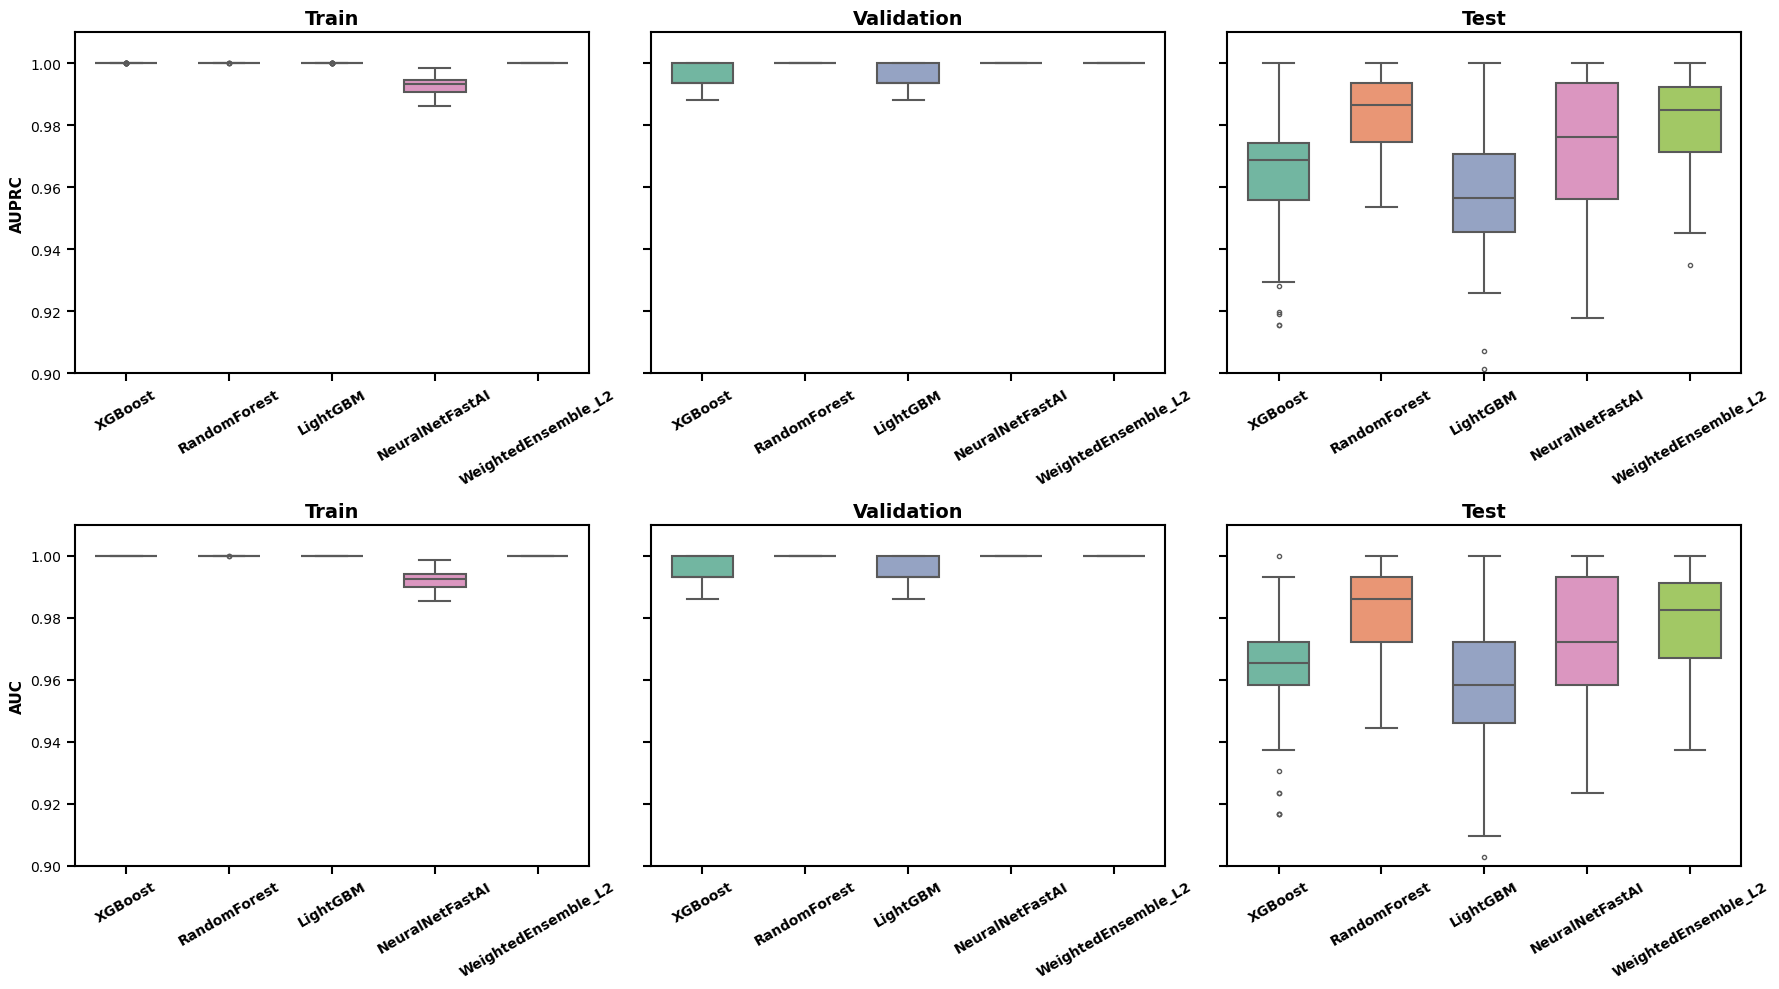

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
from sklearn.metrics import average_precision_score, roc_auc_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit

def plot_classifier_scores_by_model_with_bootstrap(data, model_dir, output_dir='ScoreBoxPlots', n_bootstrap=50):
    predictor = TabularPredictor.load(model_dir)
    raw_models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1',
                  'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

    model_name_map = {m: m.replace('_BAG_L1', '') for m in raw_models}

    # 数据划分
    train_data, temp_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)
    test_data, val_data = train_test_split(temp_data, test_size=0.5, stratify=temp_data['class'], random_state=42)

    sets = {
        'Train': train_data,
        'Validation': val_data,
        'Test': test_data
    }

    output_path = os.path.join(model_dir, output_dir)
    os.makedirs(output_path, exist_ok=True)

    all_results = []

    for model_name in raw_models:
        for set_name, df in sets.items():
            sss = StratifiedShuffleSplit(n_splits=n_bootstrap, test_size=0.5, random_state=42)
            for train_index, _ in sss.split(df, df['class']):
                sample = df.iloc[train_index]
                try:
                    y_true = sample['class']
                    y_proba = predictor.predict_proba(sample, model=model_name)
                    y_score = y_proba.iloc[:, 1] if isinstance(y_proba, pd.DataFrame) else y_proba

                    auprc = average_precision_score(y_true, y_score)
                    auc = roc_auc_score(y_true, y_score)

                    all_results.append({
                        'Model': model_name_map[model_name],
                        'Set': set_name,
                        'AUPRC': auprc,
                        'AUC': auc
                    })
                except Exception as e:
                    print(f"Model {model_name} failed on {set_name}: {e}")

    plot_df = pd.DataFrame(all_results)

    # 绘图
    fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey='row')
    metrics = ['AUPRC', 'AUC']
    sets_order = ['Train', 'Validation', 'Test']

    for i, metric in enumerate(metrics):
        for j, set_name in enumerate(sets_order):
            ax = axes[i, j]
            sns.boxplot(
                data=plot_df[plot_df['Set'] == set_name],
                x='Model',
                y=metric,
                hue='Model',
                palette='Set2',
                ax=ax,
                linewidth=1.5,     # 设置边框线更粗
                width=0.6,         # 可选：调节箱体宽度
                dodge=False,       # 避免每个 model 多次出现时分开显示
                fliersize=3        # 可选：控制离群点大小

            )

            ax.set_title(f'{set_name}', fontsize=14, fontweight='bold')
            ax.set_xlabel('')
            ax.tick_params(axis='x', labelsize=10, labelrotation=30)
            for label in ax.get_xticklabels():
                label.set_fontweight('bold')
                
            if j == 0:
                ax.set_ylabel(metric, fontsize=11, fontweight='bold')
            else:
                ax.set_ylabel('')
            ax.set_ylim(0.90, 1.01)
            ax.tick_params(axis='x', rotation=30)

            for spine in ax.spines.values():
                spine.set_linewidth(1.5)
            ax.tick_params(axis='both', width=1.5, length=6)

    plt.tight_layout()
    plot_path = os.path.join(output_path, "AUC_AUPRC_Boxplot_ByModel_Bootstrap.png")
    plt.savefig(plot_path, dpi=300)

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/ReliefF'
data = ReliefFdata 
plot_classifier_scores_by_model_with_bootstrap(data, model_dir)

In [49]:
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, recall_score, precision_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 重新加载模型和数据
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/ReliefF'
predictor = TabularPredictor.load(model_dir)
data = ReliefFdata

# 模型名称列表
models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

# 数据划分
train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)

# 用于保存结果
results = []

# 遍历每个模型并计算各项指标
for model_name in models:
    model = predictor._trainer.load_model(model_name)
    
    for set_name, df in [('Train', train_data), ('Test', test_data)]:
        y_true = df['class']
        y_proba = model.predict_proba(df)
        if isinstance(y_proba, pd.DataFrame):
            y_score = y_proba.iloc[:, 1]
        else:
            y_score = y_proba
        y_pred = (y_score >= 0.5).astype(int)

        results.append({
            'Model': model_name,
            'Set': set_name,
            'AUC': roc_auc_score(y_true, y_score),
            'Accuracy': accuracy_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred)
        })

# 转换为 DataFrame 展示
results_df = pd.DataFrame(results)
# 按 Test AUC 排序，仅保留 Test 行并根据 AUC 降序排列后提取顺序索引
test_auc_order = results_df[results_df['Set'] == 'Test'].sort_values(by='AUC', ascending=False)['Model']

# 按上述顺序重新排列整个结果 DataFrame（Validation 和 Test 行都保持）
results_df['Model'] = pd.Categorical(results_df['Model'], categories=test_auc_order, ordered=True)
results_df = results_df.sort_values(by=['Model', 'Set']).reset_index(drop=True)
results_df

,Model,Set,AUC,Accuracy,F1,Recall,Precision
0,RandomForest_BAG_L1,Test,0.992295,0.948980,0.950495,0.979592,0.923077
1,RandomForest_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
2,WeightedEnsemble_L2,Test,0.991670,0.948980,0.950495,0.979592,0.923077
3,WeightedEnsemble_L2,Train,1.000000,1.000000,1.000000,1.000000,1.000000
4,NeuralNetFastAI_BAG_L1,Test,0.989171,0.918367,0.921569,0.959184,0.886792
5,NeuralNetFastAI_BAG_L1,Train,0.992163,0.946154,0.947103,0.964103,0.930693
6,XGBoost_BAG_L1,Test,0.984173,0.928571,0.929293,0.938776,0.920000
7,XGBoost_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
8,LightGBM_BAG_L1,Test,0.983340,0.938776,0.938776,0.938776,0.938776
9,LightGBM_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000


### Binomial

In [20]:
# 加载数据集
file_path = '../Binomial/Liver_sample_BinomialSorted_selected34.csv'
Binomialdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Binomial(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Binomial/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [21]:
Liver_leaderboard_Binomial = prepare_train_test_Binomial(Binomialdata, "Liver cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       186.72 GB / 251.54 GB (74.2%)
Disk Space Avail:   8944.06 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [22]:
Liver_leaderboard_Binomial.to_csv("Liver_leaderboard_Binomial.csv", index=False)
Liver_leaderboard_Binomial

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,LightGBM_BAG_L1,0.978342,0.928571,0.928571,0.858754,0.926316,0.956522,0.897959,0.978342,0.968389,roc_auc,0.147905,0.007660,0.561056,0.147905,0.007660,0.561056,1,True,1
1,XGBoost_BAG_L1,0.975427,0.928571,0.928571,0.857321,0.927835,0.937500,0.918367,0.975427,0.968836,roc_auc,0.274075,0.030624,0.838884,0.274075,0.030624,0.838884,1,True,4
2,WeightedEnsemble_L2,0.971262,0.928571,0.928571,0.858754,0.926316,0.956522,0.897959,0.971262,0.973228,roc_auc,0.965552,0.246525,8.013832,0.002059,0.000469,0.023464,2,True,5
3,RandomForest_BAG_L1,0.964598,0.948980,0.948980,0.902671,0.946237,1.000000,0.897959,0.964598,0.968323,roc_auc,0.051925,0.102229,1.156475,0.051925,0.102229,1.156475,1,True,2
4,NeuralNetFastAI_BAG_L1,0.923782,0.632653,0.632653,0.368433,0.727273,0.578313,0.979592,0.923782,0.760289,roc_auc,0.637493,0.113203,5.995009,0.637493,0.113203,5.995009,1,True,3


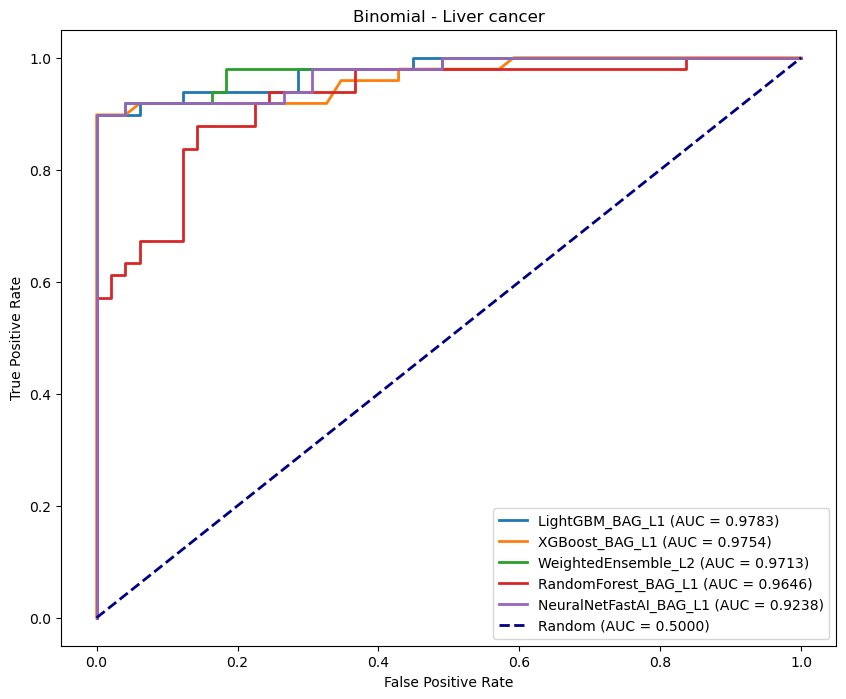

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Binomial(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Binomial - Liver cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Liver cancer/Binomial'
data = Binomialdata 
plot_roc_curves_Binomial(data, model_dir)


### biomaker分析

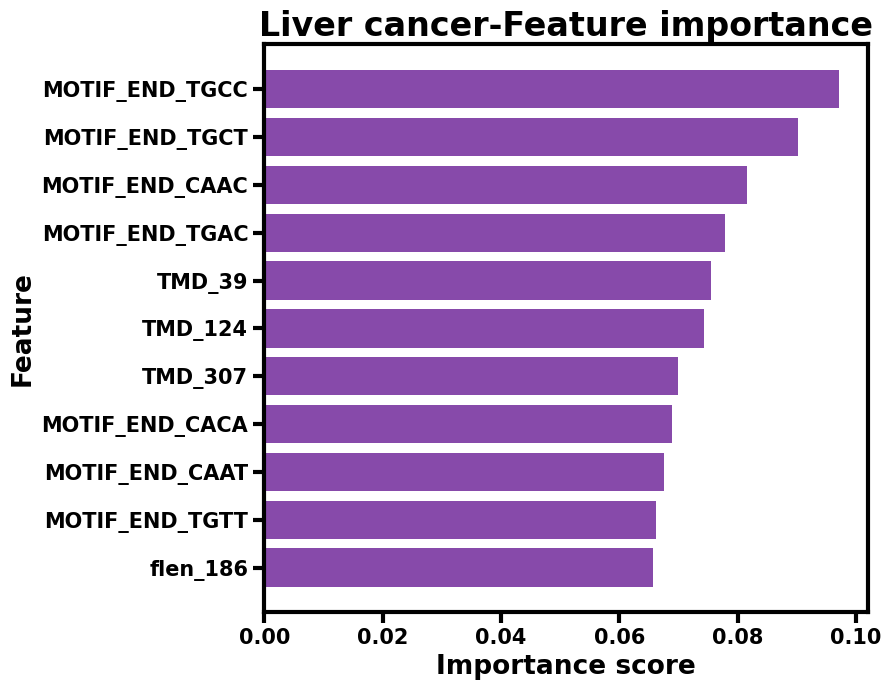

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取数据
file_path = '/home/xwluo/cfDNA/elife/ReliefF/Liver_feature_importance.csv'
df = pd.read_csv(file_path, header=None, names=['Index', 'Marker', 'Value'])

# 取前11个特征
df = df.head(11)

# 按值从大到小排序，便于绘图时从上到下展示
df = df.sort_values(by='Value', ascending=True)

# 画图
plt.figure(figsize=(9, 7))
bars = plt.barh(df['Marker'], df['Value'], color='#874AAA')

# 设置标签字体加粗
plt.xlabel("Importance score", fontsize=19, fontweight='bold')
plt.ylabel("Feature", fontsize=19, fontweight='bold')
plt.title('Liver cancer-Feature importance', fontsize=24, fontweight='bold')

# 美化坐标轴
plt.xticks(fontsize=10)
plt.yticks(fontsize=9, fontweight='bold')
plt.grid(False)


ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

plt.tight_layout()
# 保存图像
plt.savefig("Top_Feature_Barplot_Liver.png", dpi=300)
plt.show()

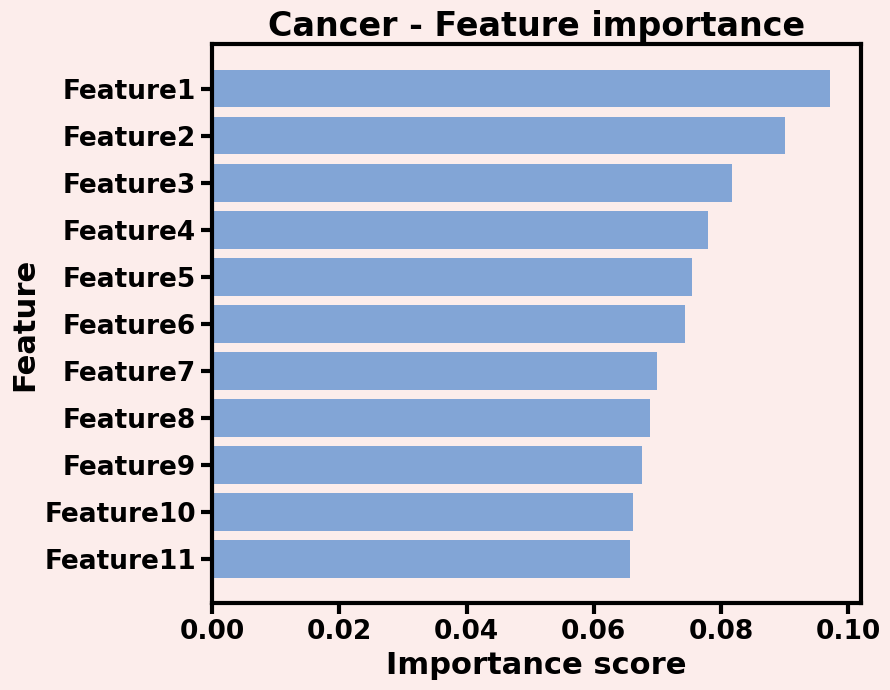

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ===== 参数 =====
file_path = '/home/xwluo/cfDNA/elife/ReliefF/Liver_feature_importance.csv'
bg_color  = '#FCEDEB'   # 背景色（可改）
title     = 'Cancer - Feature importance'
out_png   = 'Top_Feature_Barplot.png'

# ===== 读取与预处理 =====
df = pd.read_csv(file_path, header=None, names=['Index', 'Marker', 'Value'])

# 取前 11 个（如果你想取“重要性最高的 11 个”，用下一行替换本行）
df = df.head(11)
# df = df.nlargest(11, 'Value')

# 为了让最大值在最上方，按值升序排列（barh 首行在底部，末行在顶部）
df = df.sort_values(by='Value', ascending=True).reset_index(drop=True)

# 纵坐标标签：Feature1 在最上方、依次向下递增
# 对于第 i 行（从 0 开始），其标签为 Feature{n - i}
n = len(df)
y_labels = [f'Feature{n - i}' for i in range(n)]

# ===== 画图 =====
fig, ax = plt.subplots(figsize=(9, 7), facecolor=bg_color)
ax.set_facecolor(bg_color)

bars = ax.barh(y_labels, df['Value'], color='#82a5d6')  # 不指定柱色，使用默认；若需可自行加 color=

# 文本与标题
ax.set_xlabel("Importance score", fontsize=22, fontweight='bold')
ax.set_ylabel("Feature",          fontsize=22, fontweight='bold')
ax.set_title(title, fontsize=24, fontweight='bold')

# 坐标刻度样式
ax.tick_params(axis='both', width=3, length=8, labelsize=19)
for spine in ax.spines.values():
    spine.set_linewidth(3)

# y 轴加粗（与原代码保持一致）
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

# 去网格
ax.grid(False)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(19)
    tick_label.set_fontweight('bold')
fig.tight_layout()
# ax.spines['right'].set_visible(False)
# ax.spines['top'].set_visible(False)

# 保存时带上背景色
fig.savefig(out_png, dpi=300, facecolor=fig.get_facecolor())
plt.show()
